In [423]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [424]:
df = pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [425]:
df.shape

(56, 3)

In [426]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
1000.0, 1000.0]

In [427]:
len(perch_weight)

56

In [428]:
# 학습데이터, 테스트데이터 분리
train_data, test_data, train_label, test_label = train_test_split(df,perch_weight, random_state=42)
# random_state 는 테스트일때만 사용하지만, 실제적으로는 빼야함
train_data.shape

(42, 3)

In [ ]:
# 다항특성 값을 추가 
# length, height, width 
# length**2, height**2, width**2 로 변경했으나 자동생성 라이브러리 사용

# degree = 5 (5배만큼 특성값 늘림) include_bias=False (1은 재외하고 실행)
# degree 를 무작정 늘린다고 좋은 거 아님. 마이너스 정확도도 나옴 
# degree를 늘리면 과대적합에 가까움. 보통은 2,3배 정도 늘림. 
# (42.... ) : 이 부분보다 조금 낮추면 정확도가 높아짐. 특성값만 늘리면 정확도가 과대적합에 가깝게 실행됨
# poly = PolynomialFeatures(degree=7,include_bias=False) 
# poly = PolynomialFeatures(degree=20,include_bias=False) # degree 를 무작정 늘린다고 좋은 거 아님. 마이너스 정확도도 나옴

In [429]:
# 다항특성추가 - PolynomialFeatures 
# sample 양에 따라 degree 숫자 지정을 해야함
# 행보다 특성값이 높으면 과대적합이 가능성이 있음
poly = PolynomialFeatures(degree=17,include_bias=False) 
poly.fit([[2,3]])
train_poly = poly.transform([[2,3]])
train_poly

array([[2.00000000e+00, 3.00000000e+00, 4.00000000e+00, 6.00000000e+00,
        9.00000000e+00, 8.00000000e+00, 1.20000000e+01, 1.80000000e+01,
        2.70000000e+01, 1.60000000e+01, 2.40000000e+01, 3.60000000e+01,
        5.40000000e+01, 8.10000000e+01, 3.20000000e+01, 4.80000000e+01,
        7.20000000e+01, 1.08000000e+02, 1.62000000e+02, 2.43000000e+02,
        6.40000000e+01, 9.60000000e+01, 1.44000000e+02, 2.16000000e+02,
        3.24000000e+02, 4.86000000e+02, 7.29000000e+02, 1.28000000e+02,
        1.92000000e+02, 2.88000000e+02, 4.32000000e+02, 6.48000000e+02,
        9.72000000e+02, 1.45800000e+03, 2.18700000e+03, 2.56000000e+02,
        3.84000000e+02, 5.76000000e+02, 8.64000000e+02, 1.29600000e+03,
        1.94400000e+03, 2.91600000e+03, 4.37400000e+03, 6.56100000e+03,
        5.12000000e+02, 7.68000000e+02, 1.15200000e+03, 1.72800000e+03,
        2.59200000e+03, 3.88800000e+03, 5.83200000e+03, 8.74800000e+03,
        1.31220000e+04, 1.96830000e+04, 1.02400000e+03, 1.536000

In [430]:
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
print(train_poly.shape)

(42, 1139)


In [431]:
train_data[:5]

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52
6,18.7,5.20,3.12
4,17.4,4.59,2.94
41,36.0,10.61,6.74


In [432]:
train_poly[:2]

array([[1.96000000e+01, 5.14000000e+00, 3.04000000e+00, ...,
        4.62412954e+08, 2.73489374e+08, 1.61752470e+08],
       [2.20000000e+01, 5.88000000e+00, 3.52000000e+00, ...,
        5.45625431e+09, 3.26632911e+09, 1.95535348e+09]], shape=(2, 1139))

In [433]:
# 규제 : 정규화 작읍을 통해 overfiiting이 아니라 일반적인 형태로 변환 
# 규제, 정규화작업 진행 - 테스트데이터 정확도를 높일 수 있음
# StandardScaler()

ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)



In [434]:
alpha_list =[0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []
for alpha in alpha_list:

# 릿지, 라쏘 규제 (2가지 형태)
# alpha : 값을 약하게 줄지 강하게 줄지 결정하는 함수 default 값은 1
    ridge = Ridge(alpha=alpha) 
    ridge.fit(train_scaled, train_label)

    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    
    train_score.append(score)
    test_score.append(score2)
    
print('완료')


완료


In [435]:
train_score
test_score


[0.9993590115496171,
 0.9986959788210363,
 0.9974801940807378,
 0.9954095289500754,
 0.992315806255443,
 0.9846824250611482]

In [436]:
ridge = Ridge(alpha=0.1) 
ridge.fit(train_scaled, train_label)

print('train 정확도 :', score)
print('test 정확도 :', score2) 

train 정확도 : 0.9846824250611482
test 정확도 : 0.9818916802306978


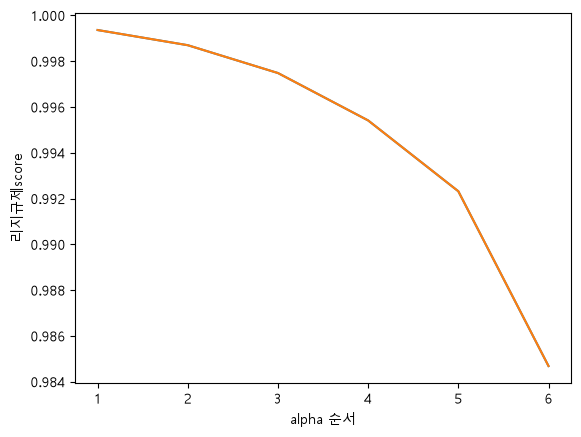

In [437]:
# 선 그래프 
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.show()

In [438]:
print('train 정확도 :', score)
print('test 정확도 :', score2) 


train 정확도 : 0.9846824250611482
test 정확도 : 0.9818916802306978


In [439]:
print(poly.get_feature_names_out()) # 어떠한 방식으로 만들어졌는지 확인 (다항특성추가 만든 형태 확인) 

['length' ' height' ' width' ... ' height^2  width^15' ' height  width^16'
 ' width^17']


In [ ]:
# * linearRegression 
# - 다중회귀 ㅣ 특성값이 여러 개인 것을 가지고 모델 학습

# * PolynomialFeatures 
# - 특성 값을 더 추가함. 이유 : 정확도를 높이기위해
# - degree 추각 

# * 과대적합 : 훈련데이터 정확도가 높은데, 테스트데이터는 현저히 정확도 떨어짐 

# * 규제 
# - 정규화작업을 해야 규제가 가능
# - Ridge 규제 
# - 옵션 : alpha 강도조절 과대적합의 문제를 해결 

In [440]:
lr = LinearRegression()
lr.fit(train_poly,train_label)

predict = lr.predict(test_poly)
print("예측 :", predict)


# test 데이터 예측 정확도가 낮기에 원본 3개로 돌라는 것보다는 정확하다는 의미, 할 때마다 예측 값이 다른 이유는 랜덤으로 진행하기에 할 때마다 다른 예측값이 나옴
# 과대적합, 과소적합

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도 :', score)
print('test 정확도 :', score2) 


예측 : [ 162.77113101  162.79491673  160.14689041  163.01538667  162.50522395
  629.86743389  128.12669465  163.20251711  838.8168149   162.82974185
 -754.35372289  162.77298931  161.68679393  178.02117583]
train 정확도 : 0.9378712937807022
test 정확도 : -1.2988231241629196
